 ### HW1: Why stochastic policy could be better sometimes
 - In this example, there are 3 states, from left to right, S1, S2, S3. Two actions right and left. At S2 (**the swtich state**), action right results in moving left, left to right. Terminal state is $G$
 - The 3 state is indistinguiable for the agent
 - The agent takes action RIGHT with probability $p$, and left with probability $1-p$, **at every state s1, s2, s3**.
 - Each transition incur a penalty of -1 (including to the terminal state $G$)
 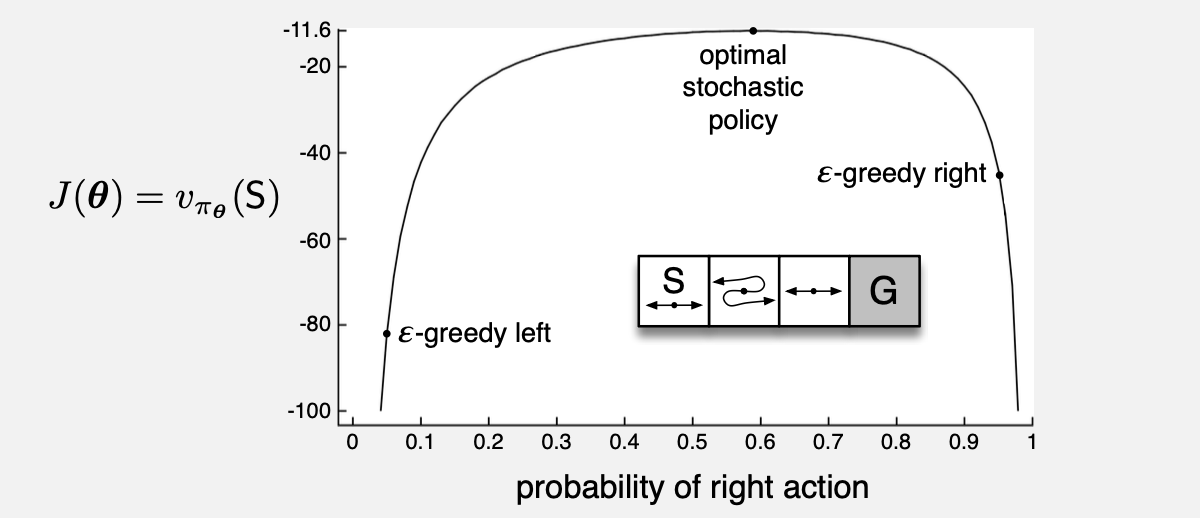
-  1 (20pts). Write down the Bellman equation for state value function $v(s)$ for $s in \{s1, s2, s3\}$
-  2 (20pts). Solve this system of equation for $v(s)$ and give solutions of $v(s1), v(s2), v(s3)$
- 3 (20pts). Plot $v(s1)$ as a function of $p$, and see if you can get same/similar picture as below (Fig 13.1 in Suton)
- 4 (20pts). In this case, is determinstic policy better, or stochastic policy?

- 5 (20pts). In a previous class, we said that by policy improvement theorem, if we use greedy policy, it should be better, why this does not apply here? You can prove by counter example by consider fixing $p$ to 0.59, and calculating the greedy policy. What policy is it? **Does the policy meet the assumption of our problem?**
 

# 1.
For $$v_\pi(s) = \sum_{a} \pi(a \mid s) \sum_{s',\,r} p(s', r \mid s, a)\,\big[\,r + \gamma\, v_\pi(s')\,\big]$$, take in
$r = -1$ and $\pi(\text{right} \mid s) = p$ we get:
$$v(s_1) = -1 + \gamma\big[\,p\,v(s_2) + (1-p)\,v(s_1)\,\big]$$
$$v(s_2) = -1 + \gamma\big[\,p\,v(s_1) + (1-p)\,v(s_3)\,\big]$$
$$v(s_3) = -1 + \gamma\,(1-p)\,v(s_2)$$

# 2.
Solve the $s_1$ and $s_3$ equations for $v(s_1)$ and $v(s_3)$ in terms of $v(s_2)$:

$$v(s_1) = \frac{-1 + \gamma p\,v(s_2)}{1-\gamma(1-p)}, \qquad v(s_3) = -1 + \gamma(1-p)\,v(s_2)$$

Substitute both into the $s_2$ equation:

$$v(s_2) = -1 + \gamma p\,\frac{-1 + \gamma p\,v(s_2)}{1-\gamma(1-p)} + \gamma(1-p)\big[-1 + \gamma(1-p)\,v(s_2)\big]$$

Multiply through by $1-\gamma(1-p)$ and collect the $v(s_2)$ terms on the left:

$$v(s_2)\Big\{\big[1-\gamma(1-p)\big]\big[1-\gamma^2(1-p)^2\big] - \gamma^2p^2\Big\} = -\big[1-\gamma^2(1-p)^2\big] - \gamma p$$

This gives

$$v(s_2) = -\frac{1 + \gamma p - \gamma^2(1-p)^2}{\big[1-\gamma(1-p)\big]\big[1-\gamma^2(1-p)^2\big] - \gamma^2p^2}$$

Back-substituting into the expressions for $v(s_1)$ and $v(s_3)$ and simplifying:

$$v(s_1) = -\frac{\big[1+\gamma(1-p)\big]\big[1-\gamma+2\gamma p\big]}{\big[1-\gamma(1-p)\big]\big[1-\gamma^2(1-p)^2\big] - \gamma^2p^2}$$

$$v(s_3) = -\frac{1-\gamma^2(1-3p+3p^2)}{\big[1-\gamma(1-p)\big]\big[1-\gamma^2(1-p)^2\big] - \gamma^2p^2}$$


# 3.

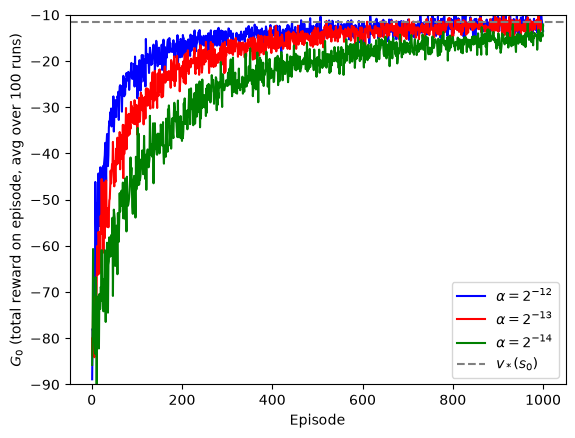

In [ ]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt

def step(state, go_right):
    # states 0,1,2 ; 3 = terminal G ; state 1 is the switched state
    if state == 1:
        go_right = not go_right
    if go_right:
        return state + 1
    return max(state - 1, 0)          # left at s1 hits the wall

def prob_right(theta, eps=0.05):
    # softmax over preferences h(right)=theta[0], h(left)=theta[1]
    p = 1.0 / (1.0 + math.exp(theta[1] - theta[0]))
    return min(max(p, eps), 1 - eps)  # keep every action prob >= eps (as in the book's code)

def reinforce(alpha, episodes=1000, gamma=1.0):
    theta = [-1.47, 1.47]             # if p around 0.05, \theta_1 - \theta_0 = \ln 19 \approx 2.944, split around 0
    returns = np.zeros(episodes)
    for ep in range(episodes):
        state, actions = 0, []
        while state != 3:              # generate one episode with the current policy
            go_right = random.random() < prob_right(theta)
            actions.append(go_right)
            state = step(state, go_right)
        T = len(actions)
        for t, go_right in enumerate(actions):   # REINFORCE update
            G = -(T - t)                          # return from step t (reward -1 per step)
            p = prob_right(theta)
            grad = [1 - p, -(1 - p)] if go_right else [-p, p]
            theta[0] += alpha * gamma**t * G * grad[0]
            theta[1] += alpha * gamma**t * G * grad[1]
        returns[ep] = -T
    return returns

runs, episodes = 100, 1000
for k, color in [(12, 'b'), (13, 'r'), (14, 'g')]:
    avg = np.mean([reinforce(2**-k, episodes) for _ in range(runs)], axis=0)
    plt.plot(np.arange(1, episodes + 1), avg, color, label=rf'$\alpha=2^{{-{k}}}$')

plt.axhline(-11.6, color='gray', linestyle='--', label=r'$v_*(s_0)$')
plt.ylim(-90, -10)
plt.xlabel('Episode')
plt.ylabel(r'$G_0$ (total reward on episode, avg over 100 runs)')
plt.legend()
plt.savefig('reinforce_corridor.png', dpi=150)
plt.show()

# 4.

Stochastic is better for we may have the worst case that the agent always hit the left wall or always tangle in the s1 and s2 if the policy determined to be this.

# 5.

The policy improvement theorem assumes the agent can pick a different action in each state, here the action is fixed. Also, because the agent can't see what state is situated, it may just choose right by one probability.But the greedy needs the agent to know exactly the state and choose action.

In [ ]:
! python -m jupyter nbconvert 11_Policy_gradient_hw.ipynb --to webpdf